<a href="https://colab.research.google.com/github/AbdullahRFA/IMDB_Sentiment_Analysis/blob/main/Module18_IMDB_Sentiment_Analysis_Abdullah_Nazmus_Sakib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment Analysis on Product Reviews (IMDB) || Customer Segmentation Analysis

**Project Description**

- In this assignment, you will work on sentiment analysis using the IMDB movie reviews dataset. The dataset contains 50,000 reviews equally divided into positive and negative sentiments. Your task is to build models that can classify whether a given review expresses a positive or negative opinion.
The focus of this project is on understanding how different text representation methods affect classification performance.
---



## import libraries and set random seeds

In [8]:

!pip install -q datasets pandas numpy


In [9]:

import random
import numpy as np
import pandas as pd

from datasets import load_dataset

# Set random seeds
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully!")
print("Random seed:", SEED)


Libraries imported successfully!
Random seed: 42


## Load the IMDB dataset

In [10]:
imdb = load_dataset("stanfordnlp/imdb")

print(imdb)


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


## Create training, validation, and test sets

In [11]:

# Split original training data into train and validation
train_valid = imdb["train"].train_test_split(
    test_size=0.10,
    seed=SEED,
    stratify_by_column="label"
)

train_ds = train_valid["train"]
val_ds = train_valid["test"]
test_ds = imdb["test"]

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Testing samples:", len(test_ds))


Training samples: 22500
Validation samples: 2500
Testing samples: 25000


In [12]:

# Display first five training reviews
for i in range(5):
    print(f"\nReview {i + 1}")
    print("Text:", train_ds[i]["text"][:500])
    print("Label:", train_ds[i]["label"])



Review 1
Text: Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link the prophecies as well as it can to what was happening in the times it was made, making it obviously dated and kind of silly.<br /><br />The reenactments look like they are out of "Unsolved Mysteries" b
Label: 0

Review 2
Text: This movie has one of the cheesiest plots I have seen. For me, that's what makes it so awesome! Fred Gwynne and Al Lewis are very good at what they achieved in the original Munsters series. While there was less slapstick, they still worked wonderfully together "comedically." I wish Yvonne De Carlo, as Lily, would have had more plot involvement. She showed that she could do comedy in the original series, but it was mostly wasted in this movie. This movie 

In [13]:

# Count positive and negative reviews
label_counts = pd.Series(
    train_ds["label"]
).value_counts().sort_index()

label_counts.index = ["Negative", "Positive"]

print(label_counts)


Negative    11250
Positive    11250
Name: count, dtype: int64


## Text Preprocessing

In [14]:

import re
import html

# Basic text cleaning function
def clean_text(text):
    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Test the function
sample_review = "<br /> THIS movie was AMAZING!!! I really loved it."

print("Original Review:")
print(sample_review)

print("\nCleaned Review:")
print(clean_text(sample_review))


Original Review:
<br /> THIS movie was AMAZING!!! I really loved it.

Cleaned Review:
this movie was amazing i really loved it


## Extract reviews and labels

In [15]:

# Extract original reviews
X_train_raw = train_ds["text"]
X_val_raw = val_ds["text"]
X_test_raw = test_ds["text"]

# Extract sentiment labels
y_train = np.array(train_ds["label"])
y_val = np.array(val_ds["label"])
y_test = np.array(test_ds["label"])

print("Training reviews:", len(X_train_raw))
print("Validation reviews:", len(X_val_raw))
print("Testing reviews:", len(X_test_raw))


Training reviews: 22500
Validation reviews: 2500
Testing reviews: 25000


## Apply basic cleaning for TF-IDF and Word2Vec

In [16]:

# Clean training, validation, and testing reviews

X_train_clean = [clean_text(review) for review in X_train_raw]

X_val_clean = [clean_text(review) for review in X_val_raw]

X_test_clean = [clean_text(review) for review in X_test_raw]

print("Preprocessing completed!")

print("\nOriginal review:")
print(X_train_raw[0][:300])

print("\nCleaned review:")
print(X_train_clean[0][:300])


Preprocessing completed!

Original review:
Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link th

Cleaned review:
every generation fully believes it is living in the end times this has been true for thousands of years now and movies like this feed on this how did they get the great orson welles to narrate this train wreck this is a documentary about the biblical prophecies of armageddon it tries to link the pro


## Tokenization for Word2Vec

In [17]:

# Tokenize reviews for Word2Vec

X_train_tokens = [review.split() for review in X_train_clean]

X_val_tokens = [review.split() for review in X_val_clean]

X_test_tokens = [review.split() for review in X_test_clean]

# Display an example
print("Cleaned review:")
print(X_train_clean[0][:200])

print("\nTokenized review:")
print(X_train_tokens[0][:20])


Cleaned review:
every generation fully believes it is living in the end times this has been true for thousands of years now and movies like this feed on this how did they get the great orson welles to narrate this tr

Tokenized review:
['every', 'generation', 'fully', 'believes', 'it', 'is', 'living', 'in', 'the', 'end', 'times', 'this', 'has', 'been', 'true', 'for', 'thousands', 'of', 'years', 'now']


## Prepare text for BERT
we'll preserve punctuation and capitalization.

In [18]:

def clean_text_for_bert(text):
    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Prepare BERT input text
X_train_bert = [
    clean_text_for_bert(review) for review in X_train_raw
]

X_val_bert = [
    clean_text_for_bert(review) for review in X_val_raw
]

X_test_bert = [
    clean_text_for_bert(review) for review in X_test_raw
]

print("Original review:")
print(X_train_raw[0][:300])

print("\nBERT-ready review:")
print(X_train_bert[0][:300])


Original review:
Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link th

BERT-ready review:
Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link th


## Verify preprocessing

In [19]:

# Verify dataset sizes
print("TF-IDF / Word2Vec")
print("Train:", len(X_train_clean))
print("Validation:", len(X_val_clean))
print("Test:", len(X_test_clean))

print("\nBERT")
print("Train:", len(X_train_bert))
print("Validation:", len(X_val_bert))
print("Test:", len(X_test_bert))

# Check for empty reviews
print("\nEmpty cleaned reviews:")
print("Train:", sum(not x for x in X_train_clean))
print("Validation:", sum(not x for x in X_val_clean))
print("Test:", sum(not x for x in X_test_clean))

# Check sentiment labels
print("\nTraining label distribution:")
print(pd.Series(y_train).value_counts().sort_index())


TF-IDF / Word2Vec
Train: 22500
Validation: 2500
Test: 25000

BERT
Train: 22500
Validation: 2500
Test: 25000

Empty cleaned reviews:
Train: 0
Validation: 0
Test: 0

Training label distribution:
0    11250
1    11250
Name: count, dtype: int64


## TF-IDF Vectorization and Sentiment Classification

In [20]:

# Import required libraries

import time
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("TF-IDF libraries imported successfully!")


TF-IDF libraries imported successfully!


In [21]:

# Initialize TF-IDF vectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Learn vocabulary and transform training reviews
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_clean)

# Transform validation and test reviews
X_val_tfidf = tfidf_vectorizer.transform(X_val_clean)

X_test_tfidf = tfidf_vectorizer.transform(X_test_clean)

print("TF-IDF vectorization completed!")

print("\nTraining matrix shape:", X_train_tfidf.shape)
print("Validation matrix shape:", X_val_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

print("\nVocabulary size:", len(tfidf_vectorizer.vocabulary_))


TF-IDF vectorization completed!

Training matrix shape: (22500, 50000)
Validation matrix shape: (2500, 50000)
Testing matrix shape: (25000, 50000)

Vocabulary size: 50000


In [22]:

# Inspect the first training review

print("Original cleaned review:")
print(X_train_clean[0][:300])

print("\nTF-IDF vector shape:")
print(X_train_tfidf[0].shape)

print("\nNon-zero TF-IDF features:")
print(X_train_tfidf[0].nnz)

# Display the first 15 non-zero features
feature_names = tfidf_vectorizer.get_feature_names_out()

row = X_train_tfidf[0]

nonzero_indices = row.indices[:15]
nonzero_values = row.data[:15]

for index, value in zip(nonzero_indices, nonzero_values):
    print(f"{feature_names[index]}: {value:.4f}")


Original cleaned review:
every generation fully believes it is living in the end times this has been true for thousands of years now and movies like this feed on this how did they get the great orson welles to narrate this train wreck this is a documentary about the biblical prophecies of armageddon it tries to link the pro

TF-IDF vector shape:
(1, 50000)

Non-zero TF-IDF features:
166
every: 0.0461
generation: 0.0873
fully: 0.0781
believes: 0.0880
it: 0.0444
is: 0.0355
living: 0.0652
in: 0.0410
the: 0.0473
end: 0.0413
times: 0.0822
this: 0.0468
has: 0.0291
been: 0.0600
true: 0.0538


## Train the Logistic Regression classifier

In [23]:

# Initialize Logistic Regression

tfidf_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

# Measure training time
start_time = time.time()

# Train the model
tfidf_model.fit(X_train_tfidf, y_train)

tfidf_training_time = time.time() - start_time

print("TF-IDF model training completed!")
print(f"Training time: {tfidf_training_time:.2f} seconds")


TF-IDF model training completed!
Training time: 5.55 seconds


## Make predictions on validation data

In [24]:

# Predict sentiment using validation data

start_time = time.time()

y_val_pred_tfidf = tfidf_model.predict(X_val_tfidf)

tfidf_prediction_time = time.time() - start_time

print("Validation predictions completed!")

print("\nActual labels:")
print(y_val[:10])

print("\nPredicted labels:")
print(y_val_pred_tfidf[:10])


Validation predictions completed!

Actual labels:
[0 1 0 0 1 1 0 1 0 0]

Predicted labels:
[0 1 1 0 1 1 0 1 0 1]


## Evaluate model performance

In [25]:

# Calculate evaluation metrics

tfidf_accuracy = accuracy_score(
    y_val, y_val_pred_tfidf
)

tfidf_precision = precision_score(
    y_val, y_val_pred_tfidf
)

tfidf_recall = recall_score(
    y_val, y_val_pred_tfidf
)

tfidf_f1 = f1_score(
    y_val, y_val_pred_tfidf
)

# Display results
print("TF-IDF + Logistic Regression Results")
print("------------------------------------")

print(f"Accuracy:  {tfidf_accuracy:.4f}")
print(f"Precision: {tfidf_precision:.4f}")
print(f"Recall:    {tfidf_recall:.4f}")
print(f"F1-score:  {tfidf_f1:.4f}")

print(f"Training time: {tfidf_training_time:.2f} seconds")
print(f"Prediction time: {tfidf_prediction_time:.2f} seconds")


TF-IDF + Logistic Regression Results
------------------------------------
Accuracy:  0.8976
Precision: 0.8932
Recall:    0.9032
F1-score:  0.8982
Training time: 5.55 seconds
Prediction time: 0.00 seconds


## Generate a classification report

In [26]:

print(
    classification_report(
        y_val,
        y_val_pred_tfidf,
        target_names=["Negative", "Positive"]
    )
)


              precision    recall  f1-score   support

    Negative       0.90      0.89      0.90      1250
    Positive       0.89      0.90      0.90      1250

    accuracy                           0.90      2500
   macro avg       0.90      0.90      0.90      2500
weighted avg       0.90      0.90      0.90      2500



## confusion matrix

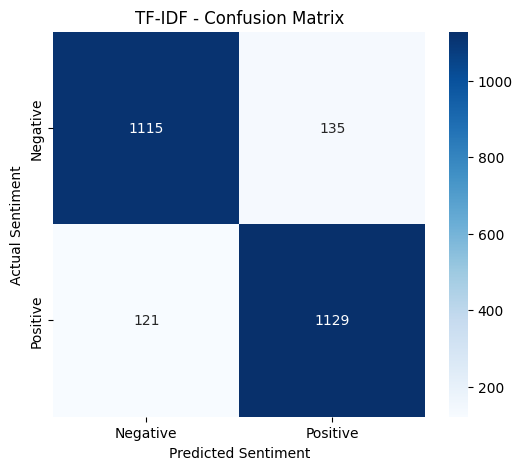

In [27]:

import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(
    y_val,
    y_val_pred_tfidf
)

# Visualize confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("TF-IDF - Confusion Matrix")

plt.show()


In [28]:

# Custom movie reviews

custom_reviews = [
    "This movie was absolutely amazing. I loved every moment.",
    "The film was terrible and extremely boring.",
    "The acting was excellent and the story was wonderful.",
    "I wasted my time watching this awful movie."
]

# Apply the same cleaning process
custom_reviews_clean = [
    clean_text(review) for review in custom_reviews
]

# Convert reviews into TF-IDF features
custom_reviews_tfidf = tfidf_vectorizer.transform(
    custom_reviews_clean
)

# Predict sentiments
custom_predictions = tfidf_model.predict(
    custom_reviews_tfidf
)

# Display predictions
for review, prediction in zip(
    custom_reviews, custom_predictions
):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("-" * 60)


Review: This movie was absolutely amazing. I loved every moment.
Predicted sentiment: Positive
------------------------------------------------------------
Review: The film was terrible and extremely boring.
Predicted sentiment: Negative
------------------------------------------------------------
Review: The acting was excellent and the story was wonderful.
Predicted sentiment: Positive
------------------------------------------------------------
Review: I wasted my time watching this awful movie.
Predicted sentiment: Negative
------------------------------------------------------------


## Save TF-IDF results for our final comparison

In [29]:

# Store TF-IDF validation results

tfidf_results = {
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": tfidf_accuracy,
    "Precision": tfidf_precision,
    "Recall": tfidf_recall,
    "F1-Score": tfidf_f1,
    "Training Time (seconds)": tfidf_training_time,
    "Prediction Time (seconds)": tfidf_prediction_time
}

print(pd.DataFrame([tfidf_results]).round(4))


                          Model  Accuracy  Precision  Recall  F1-Score  \
0  TF-IDF + Logistic Regression    0.8976     0.8932  0.9032    0.8982   

   Training Time (seconds)  Prediction Time (seconds)  
0                   5.5475                     0.0049  


## Word2Vec Embeddings and Sentiment Classification

In [30]:

!pip install -q gensim


In [31]:

from gensim.models import Word2Vec

import numpy as np
import time

print("Gensim imported successfully!")


Gensim imported successfully!


In [32]:

# Train Word2Vec model

start_time = time.time()

word2vec_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    seed=SEED,
    epochs=10
)

word2vec_training_time = time.time() - start_time

print("Word2Vec training completed!")
print(f"Training time: {word2vec_training_time:.2f} seconds")

print("\nVocabulary size:", len(word2vec_model.wv))
print("Vector dimensions:", word2vec_model.vector_size)


Word2Vec training completed!
Training time: 349.17 seconds

Vocabulary size: 45064
Vector dimensions: 100


In [33]:

# Get vector representation of a word

word = "amazing"

if word in word2vec_model.wv:
    vector = word2vec_model.wv[word]

    print("Word:", word)
    print("Vector:", vector)
    print("Vector shape:", vector.shape)
else:
    print(f"'{word}' is not in the vocabulary.")


Word: amazing
Vector: [ 0.13670434 -0.19547816 -0.17986487 -0.15370537 -0.12808596  0.6757882
 -0.15983038  0.23793341 -0.64773715 -0.41974777 -0.5069519  -0.13996719
 -0.0750367   0.33612546  0.20070904 -0.46594614  0.5077496  -0.13485645
 -0.05755818  0.31473717 -0.09461714  0.41258198 -0.19817747  0.19627348
  0.30858916  0.29661274 -0.24334268  0.39157623  0.34583902  0.02084487
 -0.10345011 -0.07207797  0.25577796  0.2279343  -0.01653543 -0.10284934
 -0.14271674 -0.43511048 -0.01492876  0.79341966 -0.11196575 -0.23795389
  0.6815157  -0.26919177  0.1540214   0.28298625  0.31263083 -0.16771038
  0.03742797  0.2086151   0.05044763 -0.48418924 -0.00918169 -0.406137
  0.17709738  0.10283439  0.0945854   0.5834358   0.06633658  0.5635695
 -0.02468079 -0.03413403  0.16978031  0.7693388   0.34130266 -0.19414687
 -0.30266106 -0.7240365   0.17811297 -0.06086415  0.1473933  -0.08992121
 -0.2789497  -0.06040793 -0.10222093 -0.06621522 -0.2655114  -0.5081482
  0.20586917 -0.11725242  0.534650

In [34]:

# Find words similar to amazing

similar_words = word2vec_model.wv.most_similar(
    "amazing",
    topn=10
)

print("Words similar to 'amazing':")

for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")


Words similar to 'amazing':
incredible: 0.8717
awesome: 0.8049
fantastic: 0.7792
extraordinary: 0.7443
stunning: 0.7414
excellent: 0.7396
outstanding: 0.7274
exceptional: 0.7045
remarkable: 0.7020
brilliant: 0.6981


In [35]:

def get_review_embedding(tokens, model, vector_size=100):
    """
    Convert a tokenized review into one vector
    by averaging its word embeddings.
    """

    word_vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    # Handle reviews with no known words
    if len(word_vectors) == 0:
        return np.zeros(vector_size)

    # Average all word vectors
    return np.mean(word_vectors, axis=0)


print("Review embedding function created!")


Review embedding function created!


In [36]:

# Generate Word2Vec review embeddings

start_time = time.time()

X_train_w2v = np.array([
    get_review_embedding(tokens, word2vec_model)
    for tokens in X_train_tokens
])

X_val_w2v = np.array([
    get_review_embedding(tokens, word2vec_model)
    for tokens in X_val_tokens
])

X_test_w2v = np.array([
    get_review_embedding(tokens, word2vec_model)
    for tokens in X_test_tokens
])

word2vec_embedding_time = time.time() - start_time

print("Review embeddings generated!")

print("\nTraining shape:", X_train_w2v.shape)
print("Validation shape:", X_val_w2v.shape)
print("Testing shape:", X_test_w2v.shape)

print(
    f"\nEmbedding generation time: "
    f"{word2vec_embedding_time:.2f} seconds"
)


Review embeddings generated!

Training shape: (22500, 100)
Validation shape: (2500, 100)
Testing shape: (25000, 100)

Embedding generation time: 20.89 seconds


In [37]:

# Initialize Logistic Regression for Word2Vec

word2vec_classifier = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

# Measure training time
start_time = time.time()

# Train classifier
word2vec_classifier.fit(
    X_train_w2v,
    y_train
)

word2vec_classifier_training_time = time.time() - start_time

print("Word2Vec classifier training completed!")

print(
    f"Classifier training time: "
    f"{word2vec_classifier_training_time:.2f} seconds"
)


Word2Vec classifier training completed!
Classifier training time: 0.30 seconds


In [38]:

# Predict sentiment on validation data

start_time = time.time()

y_val_pred_w2v = word2vec_classifier.predict(
    X_val_w2v
)

word2vec_prediction_time = time.time() - start_time

print("Word2Vec predictions completed!")

print("\nActual labels:")
print(y_val[:10])

print("\nPredicted labels:")
print(y_val_pred_w2v[:10])


Word2Vec predictions completed!

Actual labels:
[0 1 0 0 1 1 0 1 0 0]

Predicted labels:
[0 1 0 0 1 1 0 1 1 1]


In [39]:

# Calculate evaluation metrics

word2vec_accuracy = accuracy_score(
    y_val,
    y_val_pred_w2v
)

word2vec_precision = precision_score(
    y_val,
    y_val_pred_w2v
)

word2vec_recall = recall_score(
    y_val,
    y_val_pred_w2v
)

word2vec_f1 = f1_score(
    y_val,
    y_val_pred_w2v
)

# Display results

print("Word2Vec + Logistic Regression Results")
print("--------------------------------------")

print(f"Accuracy:  {word2vec_accuracy:.4f}")
print(f"Precision: {word2vec_precision:.4f}")
print(f"Recall:    {word2vec_recall:.4f}")
print(f"F1-score:  {word2vec_f1:.4f}")

print(
    f"Word2Vec training time: "
    f"{word2vec_training_time:.2f} seconds"
)

print(
    f"Classifier training time: "
    f"{word2vec_classifier_training_time:.2f} seconds"
)


Word2Vec + Logistic Regression Results
--------------------------------------
Accuracy:  0.8672
Precision: 0.8696
Recall:    0.8640
F1-score:  0.8668
Word2Vec training time: 349.17 seconds
Classifier training time: 0.30 seconds


In [40]:

# Classification report

print(
    classification_report(
        y_val,
        y_val_pred_w2v,
        target_names=["Negative", "Positive"]
    )
)


              precision    recall  f1-score   support

    Negative       0.86      0.87      0.87      1250
    Positive       0.87      0.86      0.87      1250

    accuracy                           0.87      2500
   macro avg       0.87      0.87      0.87      2500
weighted avg       0.87      0.87      0.87      2500



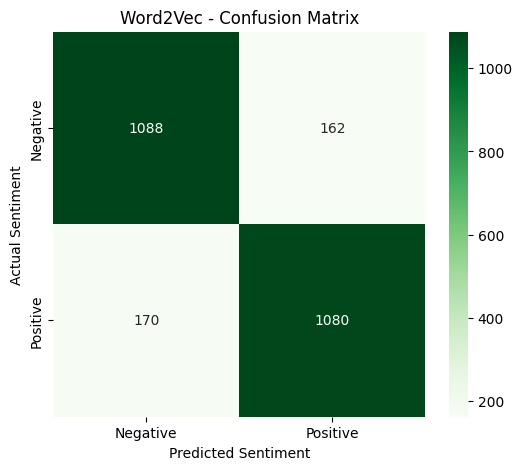

In [41]:
# Confusion matricx
import matplotlib.pyplot as plt
import seaborn as sns

cm_w2v = confusion_matrix(
    y_val,
    y_val_pred_w2v
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_w2v,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Word2Vec - Confusion Matrix")

plt.show()


In [42]:

# Store Word2Vec results

word2vec_results = {
    "Model": "Word2Vec + Logistic Regression",
    "Accuracy": word2vec_accuracy,
    "Precision": word2vec_precision,
    "Recall": word2vec_recall,
    "F1-Score": word2vec_f1,
    "Embedding Training Time (seconds)": word2vec_training_time,
    "Classifier Training Time (seconds)": word2vec_classifier_training_time,
    "Prediction Time (seconds)": word2vec_prediction_time
}

print(pd.DataFrame([word2vec_results]).round(4))


                            Model  Accuracy  Precision  Recall  F1-Score  \
0  Word2Vec + Logistic Regression    0.8672     0.8696   0.864    0.8668   

   Embedding Training Time (seconds)  Classifier Training Time (seconds)  \
0                           349.1721                              0.2982   

   Prediction Time (seconds)  
0                     0.0021  


In [43]:

# Compare first two models

initial_comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": tfidf_accuracy,
        "Precision": tfidf_precision,
        "Recall": tfidf_recall,
        "F1-Score": tfidf_f1
    },
    {
        "Model": "Word2Vec + Logistic Regression",
        "Accuracy": word2vec_accuracy,
        "Precision": word2vec_precision,
        "Recall": word2vec_recall,
        "F1-Score": word2vec_f1
    }
])

print(initial_comparison.round(4).to_string(index=False))


                         Model  Accuracy  Precision  Recall  F1-Score
  TF-IDF + Logistic Regression    0.8976     0.8932  0.9032    0.8982
Word2Vec + Logistic Regression    0.8672     0.8696  0.8640    0.8668


## BERT Embeddings and Sentiment Classification

In [44]:

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")


PyTorch version: 2.14.1+cu130
Selected device: cuda
GPU: Tesla T4


In [45]:

!pip install -q transformers


In [46]:

from transformers import AutoTokenizer, AutoModel
from torch.utils.data import DataLoader, TensorDataset

import torch
import numpy as np
import time

print("Transformers imported successfully!")


Transformers imported successfully!


In [47]:
# Load pretrained BERT tokenizer and model
MODEL_NAME = "bert-base-uncased"

# Load pretrained tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Load pretrained BERT model
bert_model = AutoModel.from_pretrained(MODEL_NAME)

# Move model to GPU or CPU
bert_model = bert_model.to(device)

# Set evaluation mode
bert_model.eval()

print("BERT tokenizer and model loaded successfully!")
print("Model:", MODEL_NAME)
print("Device:", device)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT tokenizer and model loaded successfully!
Model: bert-base-uncased
Device: cuda


In [48]:
# BERT tokenization

sample_review = X_train_bert[0]

# Tokenize one review
encoded_review = tokenizer(
    sample_review,
    padding="max_length",
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

print("Original review:")
print(sample_review[:300])

print("\nTokenized words:")
print(tokenizer.convert_ids_to_tokens(
    encoded_review["input_ids"][0][:30]
))

print("\nInput IDs shape:")
print(encoded_review["input_ids"].shape)

print("\nAttention mask shape:")
print(encoded_review["attention_mask"].shape)


Original review:
Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link th

Tokenized words:
['[CLS]', 'every', 'generation', 'fully', 'believes', 'it', 'is', 'living', 'in', 'the', 'end', 'times', '.', 'this', 'has', 'been', 'true', 'for', 'thousands', 'of', 'years', 'now', '.', 'and', 'movies', 'like', 'this', 'feed', 'on', 'this']

Input IDs shape:
torch.Size([1, 256])

Attention mask shape:
torch.Size([1, 256])


In [49]:
# Embedding function

def generate_bert_embeddings(
    texts,
    tokenizer,
    model,
    device,
    batch_size=16,
    max_length=256
):
    """
    Generate one contextual embedding per review
    using BERT mean pooling.
    """

    all_embeddings = []

    model.eval()

    start_time = time.time()

    for start in range(0, len(texts), batch_size):

        # Select a batch of reviews
        batch_texts = texts[start:start + batch_size]

        # Tokenize the batch
        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        # Move tensors to GPU or CPU
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)

        # Generate embeddings without calculating gradients
        with torch.inference_mode():

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Get token embeddings from the final hidden layer
            token_embeddings = outputs.last_hidden_state

            # Expand attention mask to match embedding dimensions
            mask = attention_mask.unsqueeze(-1).expand(
                token_embeddings.size()
            ).float()

            # Calculate masked mean pooling
            summed_embeddings = torch.sum(
                token_embeddings * mask,
                dim=1
            )

            token_counts = torch.clamp(
                mask.sum(dim=1),
                min=1e-9
            )

            review_embeddings = summed_embeddings / token_counts

            # Move embeddings to CPU and convert to NumPy
            all_embeddings.append(
                review_embeddings.cpu().numpy()
            )

        # Display progress
        processed = min(start + batch_size, len(texts))

        if processed % 1000 == 0 or processed == len(texts):
            print(f"Processed {processed}/{len(texts)} reviews")

    # Combine all batches
    all_embeddings = np.concatenate(all_embeddings, axis=0)

    total_time = time.time() - start_time

    return all_embeddings, total_time


print("BERT embedding function created!")


BERT embedding function created!


In [50]:

# Generate training embeddings

X_train_bert_embeddings, bert_train_time = generate_bert_embeddings(
    X_train_bert,
    tokenizer,
    bert_model,
    device,
    batch_size=16,
    max_length=256
)

print("\nTraining embeddings generated!")
print("Shape:", X_train_bert_embeddings.shape)


Processed 2000/22500 reviews
Processed 4000/22500 reviews
Processed 6000/22500 reviews
Processed 8000/22500 reviews
Processed 10000/22500 reviews
Processed 12000/22500 reviews
Processed 14000/22500 reviews
Processed 16000/22500 reviews
Processed 18000/22500 reviews
Processed 20000/22500 reviews
Processed 22000/22500 reviews
Processed 22500/22500 reviews

Training embeddings generated!
Shape: (22500, 768)


In [51]:

# Generate validation embeddings

X_val_bert_embeddings, bert_val_time = generate_bert_embeddings(
    X_val_bert,
    tokenizer,
    bert_model,
    device,
    batch_size=16,
    max_length=256
)

print("\nValidation embeddings generated!")
print("Shape:", X_val_bert_embeddings.shape)


Processed 2000/2500 reviews
Processed 2500/2500 reviews

Validation embeddings generated!
Shape: (2500, 768)


In [52]:

# Generate testing embeddings

X_test_bert_embeddings, bert_test_time = generate_bert_embeddings(
    X_test_bert,
    tokenizer,
    bert_model,
    device,
    batch_size=16,
    max_length=256
)

print("\nTesting embeddings generated!")
print("Shape:", X_test_bert_embeddings.shape)


Processed 2000/25000 reviews
Processed 4000/25000 reviews
Processed 6000/25000 reviews
Processed 8000/25000 reviews
Processed 10000/25000 reviews
Processed 12000/25000 reviews
Processed 14000/25000 reviews
Processed 16000/25000 reviews
Processed 18000/25000 reviews
Processed 20000/25000 reviews
Processed 22000/25000 reviews
Processed 24000/25000 reviews
Processed 25000/25000 reviews

Testing embeddings generated!
Shape: (25000, 768)


In [53]:

# Initialize classifier

bert_classifier = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

# Train classifier
start_time = time.time()

bert_classifier.fit(
    X_train_bert_embeddings,
    y_train
)

bert_classifier_training_time = time.time() - start_time

print("BERT + Logistic Regression training completed!")

print(
    f"Classifier training time: "
    f"{bert_classifier_training_time:.2f} seconds"
)


BERT + Logistic Regression training completed!
Classifier training time: 3.70 seconds


In [54]:

# Predict sentiment

start_time = time.time()

y_val_pred_bert = bert_classifier.predict(
    X_val_bert_embeddings
)

bert_prediction_time = time.time() - start_time

print("BERT validation predictions completed!")

print("\nActual labels:")
print(y_val[:10])

print("\nPredicted labels:")
print(y_val_pred_bert[:10])


BERT validation predictions completed!

Actual labels:
[0 1 0 0 1 1 0 1 0 0]

Predicted labels:
[0 1 1 0 1 1 0 1 1 1]


In [55]:

# Calculate evaluation metrics

bert_accuracy = accuracy_score(
    y_val,
    y_val_pred_bert
)

bert_precision = precision_score(
    y_val,
    y_val_pred_bert
)

bert_recall = recall_score(
    y_val,
    y_val_pred_bert
)

bert_f1 = f1_score(
    y_val,
    y_val_pred_bert
)

print("BERT + Logistic Regression Results")
print("----------------------------------")

print(f"Accuracy:  {bert_accuracy:.4f}")
print(f"Precision: {bert_precision:.4f}")
print(f"Recall:    {bert_recall:.4f}")
print(f"F1-score:  {bert_f1:.4f}")

print(
    f"Embedding generation time: "
    f"{bert_train_time + bert_val_time + bert_test_time:.2f} seconds"
)

print(
    f"Classifier training time: "
    f"{bert_classifier_training_time:.2f} seconds"
)

print(
    f"Prediction time: "
    f"{bert_prediction_time:.4f} seconds"
)


BERT + Logistic Regression Results
----------------------------------
Accuracy:  0.8812
Precision: 0.8883
Recall:    0.8720
F1-score:  0.8801
Embedding generation time: 822.34 seconds
Classifier training time: 3.70 seconds
Prediction time: 0.0204 seconds


In [56]:

print(
    classification_report(
        y_val,
        y_val_pred_bert,
        target_names=["Negative", "Positive"]
    )
)


              precision    recall  f1-score   support

    Negative       0.87      0.89      0.88      1250
    Positive       0.89      0.87      0.88      1250

    accuracy                           0.88      2500
   macro avg       0.88      0.88      0.88      2500
weighted avg       0.88      0.88      0.88      2500



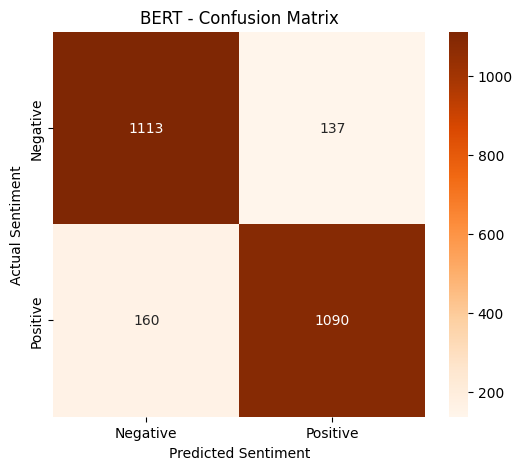

In [57]:
# Visualize the confusion matricx

cm_bert = confusion_matrix(
    y_val,
    y_val_pred_bert
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_bert,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("BERT - Confusion Matrix")

plt.show()


In [58]:

bert_results = {
    "Model": "BERT Embeddings + Logistic Regression",
    "Accuracy": bert_accuracy,
    "Precision": bert_precision,
    "Recall": bert_recall,
    "F1-Score": bert_f1,
    "Embedding Generation Time (seconds)": (
        bert_train_time + bert_val_time + bert_test_time
    ),
    "Classifier Training Time (seconds)": bert_classifier_training_time,
    "Prediction Time (seconds)": bert_prediction_time
}

print(pd.DataFrame([bert_results]).round(4))


                                   Model  Accuracy  Precision  Recall  \
0  BERT Embeddings + Logistic Regression    0.8812     0.8883   0.872   

   F1-Score  Embedding Generation Time (seconds)  \
0    0.8801                             822.3366   

   Classifier Training Time (seconds)  Prediction Time (seconds)  
0                              3.6961                     0.0204  


## Compare all three approaches

In [59]:

# Create a comparison table

all_model_results = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": tfidf_accuracy,
        "Precision": tfidf_precision,
        "Recall": tfidf_recall,
        "F1-Score": tfidf_f1
    },
    {
        "Model": "Word2Vec + Logistic Regression",
        "Accuracy": word2vec_accuracy,
        "Precision": word2vec_precision,
        "Recall": word2vec_recall,
        "F1-Score": word2vec_f1
    },
    {
        "Model": "BERT + Logistic Regression",
        "Accuracy": bert_accuracy,
        "Precision": bert_precision,
        "Recall": bert_recall,
        "F1-Score": bert_f1
    }
])

print(
    all_model_results.round(4).to_string(index=False)
)


                         Model  Accuracy  Precision  Recall  F1-Score
  TF-IDF + Logistic Regression    0.8976     0.8932  0.9032    0.8982
Word2Vec + Logistic Regression    0.8672     0.8696  0.8640    0.8668
    BERT + Logistic Regression    0.8812     0.8883  0.8720    0.8801


In [60]:

# TF-IDF test predictions

start_time = time.time()

y_test_pred_tfidf = tfidf_model.predict(X_test_tfidf)

tfidf_test_prediction_time = time.time() - start_time

print("TF-IDF test predictions completed!")

print("\nAccuracy:",
      accuracy_score(y_test, y_test_pred_tfidf))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_test_pred_tfidf,
        target_names=["Negative", "Positive"]
    )
)


TF-IDF test predictions completed!

Accuracy: 0.89892

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



In [61]:

# Word2Vec test predictions

start_time = time.time()

y_test_pred_w2v = word2vec_classifier.predict(X_test_w2v)

word2vec_test_prediction_time = time.time() - start_time

print("Word2Vec test predictions completed!")

print("\nAccuracy:",
      accuracy_score(y_test, y_test_pred_w2v))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_test_pred_w2v,
        target_names=["Negative", "Positive"]
    )
)


Word2Vec test predictions completed!

Accuracy: 0.8568

Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.87      0.86     12500
    Positive       0.86      0.85      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



In [62]:

# BERT test predictions

start_time = time.time()

y_test_pred_bert = bert_classifier.predict(
    X_test_bert_embeddings
)

bert_test_prediction_time = time.time() - start_time

print("BERT test predictions completed!")

print("\nAccuracy:",
      accuracy_score(y_test, y_test_pred_bert))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_test_pred_bert,
        target_names=["Negative", "Positive"]
    )
)


BERT test predictions completed!

Accuracy: 0.87424

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.88      0.87     12500
    Positive       0.88      0.87      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000



In [63]:

# Calculate final test metrics

def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred)
    }


tfidf_test_results = evaluate_model(
    y_test, y_test_pred_tfidf
)

word2vec_test_results = evaluate_model(
    y_test, y_test_pred_w2v
)

bert_test_results = evaluate_model(
    y_test, y_test_pred_bert
)


# Build final comparison table

final_comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        **tfidf_test_results
    },
    {
        "Model": "Word2Vec + Logistic Regression",
        **word2vec_test_results
    },
    {
        "Model": "BERT + Logistic Regression",
        **bert_test_results
    }
])

print("FINAL TEST SET PERFORMANCE")
print("=" * 75)

print(final_comparison.round(4).to_string(index=False))


FINAL TEST SET PERFORMANCE
                         Model  Accuracy  Precision  Recall  F1-Score
  TF-IDF + Logistic Regression    0.8989     0.8952  0.9036    0.8994
Word2Vec + Logistic Regression    0.8568     0.8645  0.8462    0.8553
    BERT + Logistic Regression    0.8742     0.8762  0.8716    0.8739


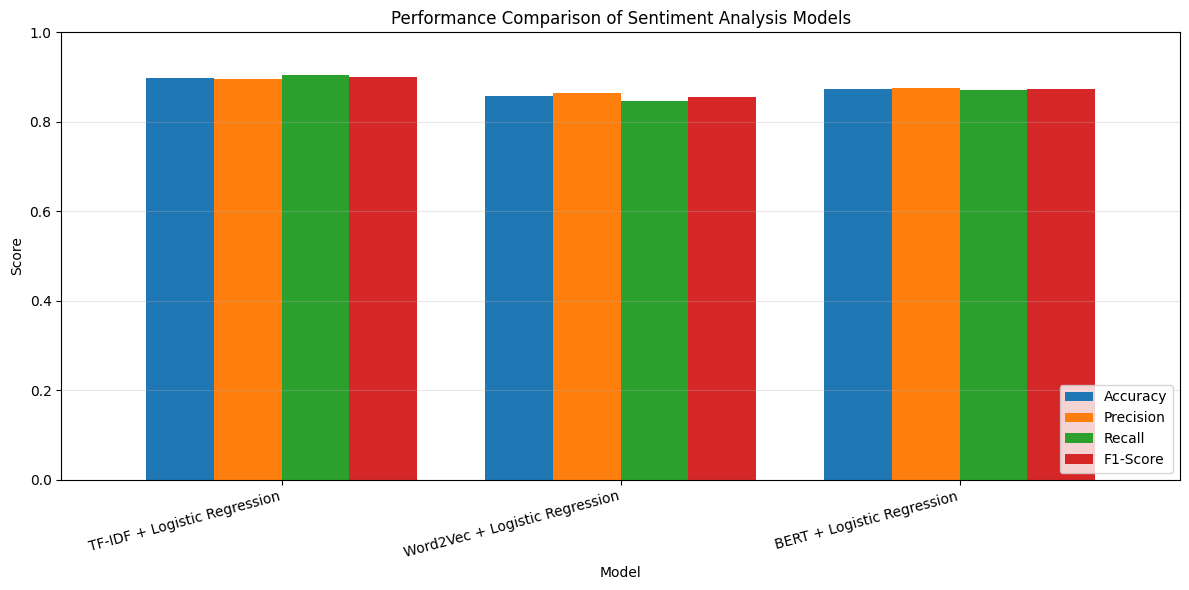

In [64]:

import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison_plot = final_comparison.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Performance Comparison of Sentiment Analysis Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [65]:

# Computational cost comparison

runtime_comparison = pd.DataFrame([
    {
        "Model": "TF-IDF",
        "Feature Training Time (s)": np.nan,
        "Classifier Training Time (s)": tfidf_training_time,
        "Test Prediction Time (s)": tfidf_test_prediction_time
    },
    {
        "Model": "Word2Vec",
        "Feature Training Time (s)": word2vec_training_time,
        "Classifier Training Time (s)": word2vec_classifier_training_time,
        "Test Prediction Time (s)": word2vec_test_prediction_time
    },
    {
        "Model": "BERT",
        "Feature Training Time (s)": (
            bert_train_time + bert_val_time + bert_test_time
        ),
        "Classifier Training Time (s)": bert_classifier_training_time,
        "Test Prediction Time (s)": bert_test_prediction_time
    }
])

print(runtime_comparison.round(2).to_string(index=False))


   Model  Feature Training Time (s)  Classifier Training Time (s)  Test Prediction Time (s)
  TF-IDF                        NaN                          5.55                      0.05
Word2Vec                     349.17                          0.30                      0.01
    BERT                     822.34                          3.70                      0.22


## Confusion matrices for all three models

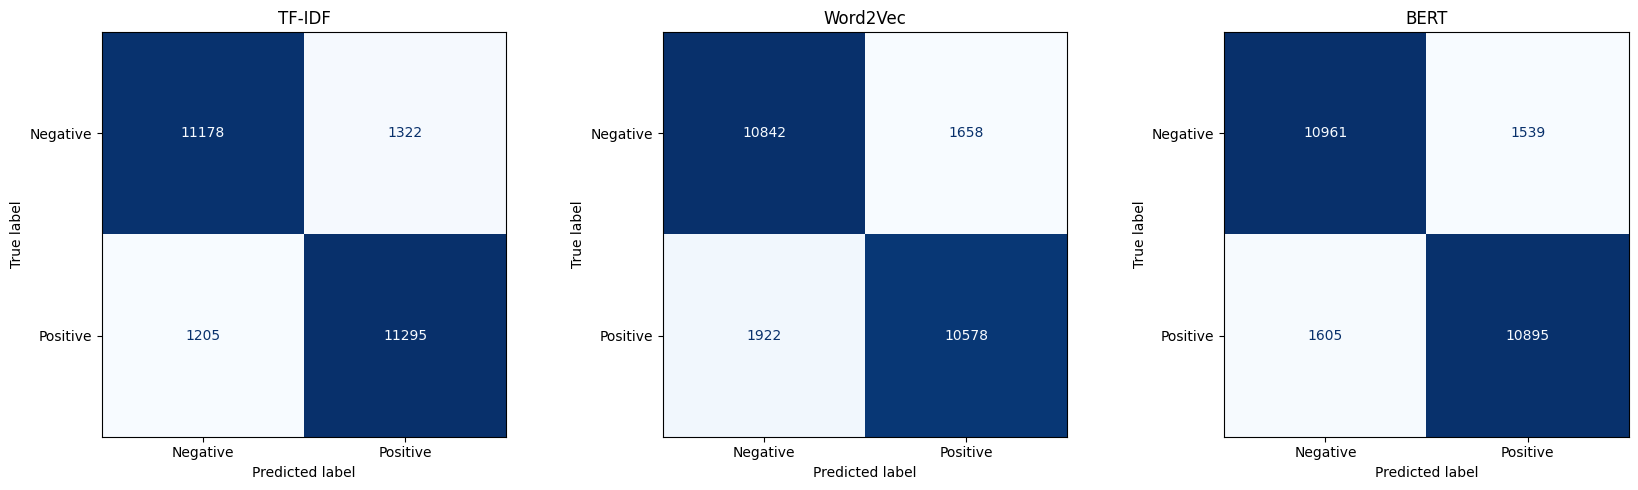

In [66]:

from sklearn.metrics import ConfusionMatrixDisplay

predictions = {
    "TF-IDF": y_test_pred_tfidf,
    "Word2Vec": y_test_pred_w2v,
    "BERT": y_test_pred_bert
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, predictions_for_model) in zip(
    axes, predictions.items()
):
    cm = confusion_matrix(y_test, predictions_for_model)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


## Error analysis

In [67]:

# Collect misclassified test reviews

def show_misclassified_reviews(
    texts,
    y_true,
    y_pred,
    model_name,
    number_of_examples=5
):
    wrong_indices = np.where(y_true != y_pred)[0]

    print(f"\n{model_name} - Misclassified Reviews")
    print("=" * 70)

    for index in wrong_indices[:number_of_examples]:

        actual = "Positive" if y_true[index] == 1 else "Negative"

        predicted = "Positive" if y_pred[index] == 1 else "Negative"

        print(f"\nReview index: {index}")
        print("Actual sentiment:", actual)
        print("Predicted sentiment:", predicted)
        print("Review:", texts[index][:700])
        print("-" * 70)


show_misclassified_reviews(
    X_test_raw,
    y_test,
    y_test_pred_tfidf,
    "TF-IDF"
)

show_misclassified_reviews(
    X_test_raw,
    y_test,
    y_test_pred_w2v,
    "Word2Vec"
)

show_misclassified_reviews(
    X_test_raw,
    y_test,
    y_test_pred_bert,
    "BERT"
)



TF-IDF - Misclassified Reviews

Review index: 4
Actual sentiment: Negative
Predicted sentiment: Positive
Review: First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. This movie is much better than any of the movies the other action guys (Segal and Dolph) have thought about putting out the past few years. Van Damme is good in the movie, the movie is only worth watching to Van Damme fans. It is not as good as Wake of Death (which i highly recommend to anyone of likes Van Damme) or In hell but, in my opinion it's worth watching. It has the same type of feel to it as Nowhere to Run. Good fun stuff!
----------------------------------------------------------------------

Review index: 18
Actual sentiment: Negative
Predicted sentiment: Positive
Review: Ben, (Rupert Grint), is a deeply unhappy adolescent, the so

## Compare validation and test performance

In [68]:

# Compare validation and test accuracy

generalization_comparison = pd.DataFrame([
    {
        "Model": "TF-IDF",
        "Validation Accuracy": tfidf_accuracy,
        "Test Accuracy": tfidf_test_results["Accuracy"]
    },
    {
        "Model": "Word2Vec",
        "Validation Accuracy": word2vec_accuracy,
        "Test Accuracy": word2vec_test_results["Accuracy"]
    },
    {
        "Model": "BERT",
        "Validation Accuracy": bert_accuracy,
        "Test Accuracy": bert_test_results["Accuracy"]
    }
])

generalization_comparison["Difference"] = (
    generalization_comparison["Test Accuracy"]
    - generalization_comparison["Validation Accuracy"]
)

print(generalization_comparison.round(4).to_string(index=False))


   Model  Validation Accuracy  Test Accuracy  Difference
  TF-IDF               0.8976         0.8989      0.0013
Word2Vec               0.8672         0.8568     -0.0104
    BERT               0.8812         0.8742     -0.0070


### Analysis of Model Performance

 **TF-IDF + Logistic Regression performed best overall**,
- achieving the highest test accuracy (89.89%), precision (89.52%), recall (90.36%), and F1-score (89.94%). Its use of unigrams and bigrams helped capture important words and phrases that indicate positive or negative sentiment.

 **Word2Vec + Logistic Regression achieved the lowest performance,**
- with 85.68% accuracy and an 85.53% F1-score. Although Word2Vec captures semantic relationships between words, averaging word embeddings into a single review vector may lose important word order and contextual information.

**BERT + Logistic Regression achieved moderate performance**,
- with 87.42% accuracy and an 87.39% F1-score. It provided contextual word representations, but the model used frozen BERT embeddings rather than fine-tuning BERT for sentiment classification, which may have limited its performance.

**Training time varied significantly across approaches.**
- Word2Vec feature training took 349.17 seconds, while BERT feature extraction took 822.34 seconds. TF-IDF's feature training time was not recorded, but its Logistic Regression classifier required only 5.55 seconds to train.

**TF-IDF was the most practical approach in this experiment,**
- offering the best predictive performance with very fast test prediction (0.05 seconds). Word2Vec had the fastest prediction time (0.01 seconds), while BERT was the slowest (0.22 seconds).

**Resource usage was another important trade-off.**
- TF-IDF produces sparse numerical features and is relatively efficient. Word2Vec requires additional time to train word embeddings and generate review representations. BERT requires substantially more computational resources and memory for transformer-based embedding extraction.

**Validation and test performance were consistent for TF-IDF.**
- Its accuracy increased slightly from 89.76% to 89.89%, a difference of only 0.13 percentage points. This suggests stable generalization to unseen reviews.

**Word2Vec and BERT showed small performance drops on the test set**.
- Word2Vec decreased by 1.04 percentage points, while BERT decreased by 0.70 percentage points. These differences suggest slightly weaker generalization compared with TF-IDF.

**Common classification errors may involve reviews with mixed sentiment, sarcasm, negation, or context-dependent expressions.**
- For example, a review may contain positive words while expressing an overall negative opinion. TF-IDF may struggle to understand deeper context, while Word2Vec's average embeddings can lose word order. BERT can capture more context, but its predictions are not always correct. Reviewing the misclassified examples and confusion matrices can help identify these error patterns.



**Overall finding:**
- TF-IDF + Logistic Regression was the best approach for this IMDB sentiment analysis experiment, providing the highest accuracy and F1-score while maintaining low prediction time. Although BERT offers richer contextual representations, its additional computational cost did not translate into better performance in this frozen-embedding setup.